# Task

Keep using the One-piece [competition case](https://www.kaggle.com/t/cbb5a354db814e00b14a786ae5eded1b).

Build on your Assignment 4. Some ideas to improve the prediction.

1. **factors!** Create factors by using principle components and use them in the regression to see if there is any improvement. You might have done some work in Assignment 4 already, but more details can still exist.

    - Shall I use all variables or part of it?
    - Which one goes first, LASSO or PCA? Or can I have layers of them? For example, LASSO first, PCA after, and then LASSO again.
    - How many components should I use?
    - Should the factors be added to or used to replace the existing regressors?
    - Is there a chance to use interactions? Interactions of $X$ or PCs?
    - How about patial least squares?


1. There is **NO need to do everything**. Find your interest first.
It will be great if you can create new logical ideas.
1. Get the test sample for prediction and submit your results on Kaggle to get your Kaggle score screenshot. Show the screenshot in the PDF file.
1. The Kaggle score is a good reference for us to understand a model's OOS performance, but it does not dominate the marking scheme.

**Note**

- All instructions in Assignment 1 apply.
- Use $\leq 300$ words.

In [31]:
# ==============================================================================
# Environment Configuration & In-Class Library Imports (Weeks 03-09 Strictly)
# ==============================================================================
import os
import sys
import json
import zipfile
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Preprocessing, Clustering, PCA & Linear Estimation (Weeks 03-09)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LassoCV, Lasso, Ridge, ElasticNet, LinearRegression
from sklearn.model_selection import KFold, cross_val_predict, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from kaggle.api.kaggle_api_extended import KaggleApi

# Plot Styling Configuration
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("[INITIALIZED] In-class statistical learning environment configured successfully (Weeks 03-09).")

[INITIALIZED] In-class statistical learning environment configured successfully (Weeks 03-09).


In [32]:
# ==============================================================================
# Kaggle API Authentication & Dataset Ingestion
# ==============================================================================
api_key = "KGAT_6fde8d22951b85624abc2b173cad0660"
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
with open(os.path.expanduser("~/.kaggle/access_token"), "w") as f:
    f.write(api_key)

api = KaggleApi()
try:
    api.authenticate()
    print("[KAGGLE] Authenticated successfully with Kaggle API.")
except Exception as e:
    print(f"[KAGGLE NOTICE] API Auth skipped/using local data: {e}")

# Resolve Data Directory Across Workspace & Assignment Directory Contexts
data_candidates = [
    os.path.abspath("kaggle_data"),
    os.path.abspath("../kaggle_data"),
    os.path.abspath("assignment/kaggle_data"),
    os.path.abspath("../assignment/kaggle_data")
]
data_dir = next((d for d in data_candidates if os.path.exists(d)), None)

if not data_dir:
    raise FileNotFoundError("kaggle_data directory not found in workspace candidate paths.")

print(f"[DATA DIR] Utilizing verified data source: {data_dir}")

train_df = pd.read_csv(os.path.join(data_dir, "train_data.csv"))
test_df = pd.read_csv(os.path.join(data_dir, "test_data.csv"))

print(f"[DATA LOADED] Train Matrix: {train_df.shape} | Test Matrix: {test_df.shape}")

X = train_df.drop(columns=['ID', 'Y'])
y = train_df['Y'].values
X_test = test_df.drop(columns=['ID'])
test_ids = test_df['ID'].values

feature_names = list(X.columns)
print(f"[VERIFIED] Features: {len(feature_names)} predictors | Target N = {len(y)} | Test N = {len(X_test)}")

[KAGGLE] Authenticated successfully with Kaggle API.
[DATA DIR] Utilizing verified data source: /Users/chenxinzheng/Desktop/UniMelb/90025 ADA/assignment/kaggle_data
[DATA LOADED] Train Matrix: (2400, 52) | Test Matrix: (1600, 51)
[VERIFIED] Features: 50 predictors | Target N = 2400 | Test N = 1600


## Step 1: Exploratory Factor Analysis & Diagnostic Spectral Properties (Week 09)



In [33]:
# ==============================================================================
# Step 1: Principal Component Factorisation & Spectral Diagnostics (Week 09)
# ==============================================================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_test_scaled = scaler.transform(X_test)

# 1. Full Spectrum PCA Factorisation
pca_full = PCA(n_components=50, random_state=RANDOM_STATE)
X_pca_scores = pca_full.fit_transform(X_scaled)
exp_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(exp_var)
eigenvalues = pca_full.explained_variance_

print("=" * 70)
print("WEEK 09 SPECTRAL FACTORISATION DIAGNOSTIC SUMMARY")
print("=" * 70)
print(f"Top 5 Eigenvalues (lambda): {eigenvalues[:5].round(3)}")
print(f"Top 5 Explained Variance  : {exp_var[:5].round(4)}")
print(f"Cumulative Variance (Top 5): {cum_var[4]:.4f} ({cum_var[4]*100:.2f}%)")
print(f"Dominant Factor PC1 Variance: {exp_var[0]*100:.2f}% (Eigenvalue = {eigenvalues[0]:.2f})")
print(f"Tail Factor Range (PC2-PC50): {eigenvalues[1]:.2f} to {eigenvalues[-1]:.2f} (Uniform Noise Floor)")

# 2. Variable Loadings Analysis (Week 09 Bottom-Up Interpretation)
loadings_df = pd.DataFrame(pca_full.components_[:3, :], columns=X.columns, index=["PC1", "PC2", "PC3"])
print("\n" + "=" * 70)
print("Top Positive & Negative Loadings on Dominant Factor PC1:")
print("=" * 70)
print("Top Positive Loadings (PC1):\n", loadings_df.loc["PC1"].nlargest(5).round(4))
print("\nTop Negative Loadings (PC1):\n", loadings_df.loc["PC1"].nsmallest(5).round(4))

# 3. Correlation of Extracted Factors with Target Variable Y
pc_correlations = pd.Series(
    [np.corrcoef(X_pca_scores[:, i], y)[0, 1] for i in range(50)],
    index=[f"PC{i+1}" for i in range(50)]
)
print("\n" + "=" * 70)
print("Top 5 Principal Components by Absolute Correlation with Target Y:")
print("=" * 70)
display(pc_correlations.abs().nlargest(5).to_frame(name="Absolute Pearson Correlation |r|").round(4))

WEEK 09 SPECTRAL FACTORISATION DIAGNOSTIC SUMMARY
Top 5 Eigenvalues (lambda): [10.655  1.018  1.011  1.004  0.983]
Top 5 Explained Variance  : [0.213  0.0204 0.0202 0.0201 0.0197]
Cumulative Variance (Top 5): 0.2933 (29.33%)
Dominant Factor PC1 Variance: 21.30% (Eigenvalue = 10.66)
Tail Factor Range (PC2-PC50): 1.02 to 0.61 (Uniform Noise Floor)

Top Positive & Negative Loadings on Dominant Factor PC1:
Top Positive Loadings (PC1):
 X21    0.1534
X20    0.1524
X18    0.1518
X38    0.1512
X7     0.1508
Name: PC1, dtype: float64

Top Negative Loadings (PC1):
 X11    0.1304
X45    0.1321
X17    0.1323
X22    0.1324
X5     0.1328
Name: PC1, dtype: float64

Top 5 Principal Components by Absolute Correlation with Target Y:


,Absolute Pearson Correlation |r|
PC1,0.6228
PC24,0.2105
PC16,0.1570
PC19,0.1375
PC13,0.1034


## Step 2: Addressing Assignment Prompts — Systematic Factor Experiments (Weeks 03–09)


In [34]:
# ==============================================================================
# Step 2: Methodological Factor Experiments Addressing All Core Prompts
# ==============================================================================
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ------------------------------------------------------------------------------
# Experiment 1: Variable Scope & Screening Diagnostics
# ------------------------------------------------------------------------------
lasso_screener = LassoCV(cv=5, random_state=RANDOM_STATE, max_iter=10000).fit(X_scaled, y)
screened_vars = X.columns[lasso_screener.coef_ != 0].tolist()
print(f"[EXP 1] Raw Variables: {X.shape[1]} | Screened Active Linear Regressors: {len(screened_vars)}")

# ------------------------------------------------------------------------------
# Experiment 2: Sequencing & Layering (PCR vs. Supervised PC Selection)
# ------------------------------------------------------------------------------
pipe_pcr_50 = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=50, random_state=RANDOM_STATE)),
    ('ols', LinearRegression())
])
oof_pcr = cross_val_predict(pipe_pcr_50, X, y, cv=kf, n_jobs=-1)
rmse_pcr = np.sqrt(mean_squared_error(y, oof_pcr))

pipe_lasso_pcs = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=50, random_state=RANDOM_STATE)),
    ('lasso_cv', LassoCV(cv=5, random_state=RANDOM_STATE, max_iter=10000))
])
oof_lasso_pcs = cross_val_predict(pipe_lasso_pcs, X, y, cv=kf, n_jobs=-1)
rmse_lasso_pcs = np.sqrt(mean_squared_error(y, oof_lasso_pcs))
print(f"[EXP 2] PCR (PCA->OLS) RMSE: {rmse_pcr:.4f} | Supervised PC (PCA->LASSO) RMSE: {rmse_lasso_pcs:.4f}")

# ------------------------------------------------------------------------------
# Experiment 3: FWL Factor-Idiosyncratic Residual Decomposition
# ------------------------------------------------------------------------------
e_matrix = np.zeros_like(X_scaled)
for j in range(50):
    reg = LinearRegression().fit(X_pca_scores[:, :1], X_scaled[:, j])
    e_matrix[:, j] = X_scaled[:, j] - reg.predict(X_pca_scores[:, :1])

y_reg = LinearRegression().fit(X_pca_scores[:, :1], y)
y_resid = y - y_reg.predict(X_pca_scores[:, :1])
r_e48 = np.corrcoef(e_matrix[:, X.columns.get_loc('X48')], y_resid)[0, 1]
r_e34 = np.corrcoef(e_matrix[:, X.columns.get_loc('X34')], y_resid)[0, 1]
print(f"[EXP 3] Factor-Idiosyncratic Signals: r(e_48, y_resid) = {r_e48:.4f} | r(e_34, y_resid) = {r_e34:.4f}")

X_idio_df = pd.DataFrame({
    'PC1': X_pca_scores[:, 0],
    'PC2': X_pca_scores[:, 1],
    'PC1_sq': X_pca_scores[:, 0]**2,
    'e_48': e_matrix[:, X.columns.get_loc('X48')],
    'e_34': e_matrix[:, X.columns.get_loc('X34')],
    'e_27': e_matrix[:, X.columns.get_loc('X27')],
    'e_21': e_matrix[:, X.columns.get_loc('X21')],
    'PC1_inter_e48': X_pca_scores[:, 0] * e_matrix[:, X.columns.get_loc('X48')],
    'PC1_inter_e34': X_pca_scores[:, 0] * e_matrix[:, X.columns.get_loc('X34')],
    'PC1_inter_e27': X_pca_scores[:, 0] * e_matrix[:, X.columns.get_loc('X27')],
})
oof_idio = cross_val_predict(LinearRegression(), X_idio_df, y, cv=kf, n_jobs=-1)
rmse_idio = np.sqrt(mean_squared_error(y, oof_idio))
print(f"  --> Factor-Idiosyncratic Model RMSE = {rmse_idio:.4f}")

# ------------------------------------------------------------------------------
# Experiment 4: Week 09 K-Means Clustering & Regime-Switching Slopes
# ------------------------------------------------------------------------------
kmeans_3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
cluster_labels = kmeans_3.fit_predict(X_scaled)
cluster_dummies = pd.get_dummies(cluster_labels, prefix='cluster', drop_first=False).values

regime_feats = [cluster_dummies[:, 1:]]
for k in range(3):
    regime_feats.append(cluster_dummies[:, k:k+1] * X_scaled[:, [X.columns.get_loc('X34')]])
    regime_feats.append(cluster_dummies[:, k:k+1] * X_scaled[:, [X.columns.get_loc('X48')]])
    regime_feats.append(cluster_dummies[:, k:k+1] * X_pca_scores[:, 0:1])

X_regime = np.hstack(regime_feats)
oof_regime = cross_val_predict(LinearRegression(), X_regime, y, cv=kf, n_jobs=-1)
rmse_regime = np.sqrt(mean_squared_error(y, oof_regime))
print(f"[EXP 4] K-Means Latent Regime-Switching Model RMSE = {rmse_regime:.4f}")

[EXP 1] Raw Variables: 50 | Screened Active Linear Regressors: 38
[EXP 2] PCR (PCA->OLS) RMSE: 3.0721 | Supervised PC (PCA->LASSO) RMSE: 3.0692
[EXP 3] Factor-Idiosyncratic Signals: r(e_48, y_resid) = -0.3835 | r(e_34, y_resid) = 0.2024
  --> Factor-Idiosyncratic Model RMSE = 3.2174
[EXP 4] K-Means Latent Regime-Switching Model RMSE = 3.3065


## Step 3: Pre-Model Feature Engineering & Category 3 Econometric Model Averaging



In [35]:
# ==============================================================================
# Step 3: Pre-Model Feature Space Engineering & Factor-Augmented Stacking
# ==============================================================================

print("Engineering Expanded Pre-Model Feature Space...")

# 1. Base Degree-2 Polynomial Expansion over Screened Regressors
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly_arr = poly.fit_transform(X[screened_vars])
poly_cols = poly.get_feature_names_out(screened_vars)
X_poly = pd.DataFrame(X_poly_arr, columns=poly_cols, index=X.index)

X_test_poly_arr = poly.transform(X_test[screened_vars])
X_test_poly = pd.DataFrame(X_test_poly_arr, columns=poly_cols, index=X_test.index)

# 2. Cubic Curvature Features (Week 03)
for var in ['X48', 'X27', 'X34', 'X42', 'X10']:
    X_poly[f"{var}^3"] = X[var] ** 3
    X_test_poly[f"{var}^3"] = X_test[var] ** 3

# 3. Median RDD Threshold Cutoffs (Week 07)
for var in ["X48", "X34", "X27", "X21"]:
    c = X[var].median()
    X_poly[f"{var}_rdd_thresh"] = (X[var] > c).astype(float)
    X_test_poly[f"{var}_rdd_thresh"] = (X_test[var] > c).astype(float)

# 4. Demeaned Covariate Adjustment Interactions (Week 06)
x34_c_train = X["X34"] - X["X34"].mean()
x34_c_test = X_test["X34"] - X_test["X34"].mean()
for var in ["X21", "X45", "X46", "X48"]:
    X_poly[f"x34_inter_{var}_centered"] = x34_c_train * (X[var] - X[var].mean())
    X_test_poly[f"x34_inter_{var}_centered"] = x34_c_test * (X_test[var] - X_test[var].mean())

# 5. PRE-MODEL FEATURE ENGINEERING DISCOVERIES:
# Rescuing prematurely pruned variables via X34 interactions & thresholds
X_poly['X25_rdd_thresh'] = (X['X25'] > X['X25'].median()).astype(float)
X_test_poly['X25_rdd_thresh'] = (X_test['X25'] > X['X25'].median()).astype(float)

X_poly['X28_rdd_thresh'] = (X['X28'] > X['X28'].median()).astype(float)
X_test_poly['X28_rdd_thresh'] = (X_test['X28'] > X['X28'].median()).astype(float)

for v in ['X8', 'X33', 'X13', 'X4', 'X36', 'X44', 'X49', 'X50']:
    X_poly[f'{v}_inter_X34'] = X[v] * X['X34']
    X_test_poly[f'{v}_inter_X34'] = X_test[v] * X_test['X34']

# 6. Continuous RDD Splines / Hinge Functions (Weeks 03 & 07)
X_poly['X34_hinge_neg05'] = np.maximum(0, X['X34'] + 0.5)
X_test_poly['X34_hinge_neg05'] = np.maximum(0, X_test['X34'] + 0.5)

X_poly['X48_hinge_zero'] = np.maximum(0, X['X48'])
X_test_poly['X48_hinge_zero'] = np.maximum(0, X_test['X48'])

# 7. Pre-Model Factor Manifolds & Cross-Interactions (Week 09)
X_poly['PC1'] = X_pca_scores[:, 0]
X_test_poly['PC1'] = pca_full.transform(X_test_scaled)[:, 0]

X_poly['PC2'] = X_pca_scores[:, 1]
X_test_poly['PC2'] = pca_full.transform(X_test_scaled)[:, 1]

X_poly['PC1_sq'] = X_pca_scores[:, 0] ** 2
X_test_poly['PC1_sq'] = pca_full.transform(X_test_scaled)[:, 0] ** 2

X_poly['PC1_inter_PC2'] = X_pca_scores[:, 0] * X_pca_scores[:, 1]
X_test_poly['PC1_inter_PC2'] = pca_full.transform(X_test_scaled)[:, 0] * pca_full.transform(X_test_scaled)[:, 1]

X_poly['PC1_inter_X34'] = X_pca_scores[:, 0] * X_scaled[:, X.columns.get_loc('X34')]
X_test_poly['PC1_inter_X34'] = pca_full.transform(X_test_scaled)[:, 0] * X_test_scaled[:, X.columns.get_loc('X34')]

X_poly['PC1_inter_X48'] = X_pca_scores[:, 0] * X_scaled[:, X.columns.get_loc('X48')]
X_test_poly['PC1_inter_X48'] = pca_full.transform(X_test_scaled)[:, 0] * X_test_scaled[:, X.columns.get_loc('X48')]

print(f"[PRE-MODEL SPACE] P = {X_poly.shape[1]} engineered features successfully generated.")

# Standardize Pre-Model Regressor Matrix
scaler_poly = StandardScaler()
X_poly_scaled = scaler_poly.fit_transform(X_poly)
X_test_poly_scaled = scaler_poly.transform(X_test_poly)

# 2. Fit Candidate In-Class Estimators Across Methodological Families
print("\nEvaluating Candidate Estimators via 5-Fold Cross-Validation...")

# [Baseline] Raw 50-variable OLS
pipe_ols = Pipeline([('scaler', StandardScaler()), ('ols', LinearRegression())])
oof_ols = cross_val_predict(pipe_ols, X, y, cv=kf, n_jobs=-1)

# [Assignment 4 Baseline] Polynomial Lasso on original P=792
# (Constructed purely for baseline benchmark comparison)
X_poly_a4 = X_poly[poly_cols].copy()
for var in ['X48', 'X27', 'X34', 'X42', 'X10']:
    X_poly_a4[f"{var}^3"] = X[var] ** 3
for var in ["X48", "X34", "X27", "X21"]:
    c = X[var].median()
    X_poly_a4[f"{var}_rdd_thresh"] = (X[var] > c).astype(float)
for var in ["X21", "X45", "X46", "X48"]:
    X_poly_a4[f"x34_inter_{var}_centered"] = x34_c_train * (X[var] - X[var].mean())
X_poly_a4_scaled = StandardScaler().fit_transform(X_poly_a4)

pipe_lasso_a4 = Pipeline([('lasso', Lasso(alpha=0.04, random_state=RANDOM_STATE, max_iter=5000))])
oof_lasso_a4 = cross_val_predict(pipe_lasso_a4, X_poly_a4_scaled, y, cv=kf, n_jobs=-1)

# [New Pre-Engineered Model 1] High-D Lasso on Pre-Model Space
pipe_lasso_new = Pipeline([('lasso', Lasso(alpha=0.048, random_state=RANDOM_STATE, max_iter=5000))])
oof_lasso_new = cross_val_predict(pipe_lasso_new, X_poly_scaled, y, cv=kf, n_jobs=-1)

# [New Pre-Engineered Model 2] ElasticNet on Pre-Model Space
pipe_enet_new = Pipeline([('enet', ElasticNet(alpha=0.05, l1_ratio=0.85, random_state=RANDOM_STATE, max_iter=5000))])
oof_enet_new = cross_val_predict(pipe_enet_new, X_poly_scaled, y, cv=kf, n_jobs=-1)

# [New Pre-Engineered Model 3] Ridge on Pre-Model Space
pipe_ridge_new = Pipeline([('ridge', Ridge(alpha=40.0))])
oof_ridge_new = cross_val_predict(pipe_ridge_new, X_poly_scaled, y, cv=kf, n_jobs=-1)

# 3. Winning Model: Category 3 Econometric Model Averaging (NNLS Stacking)
meta_blend_matrix = np.column_stack([
    oof_lasso_new,
    oof_enet_new,
    oof_ridge_new,
    oof_lasso_a4,
    oof_lasso_pcs,
    oof_idio
])

meta_nnls = LinearRegression(positive=True)
meta_nnls.fit(meta_blend_matrix, y)
oof_factor_ensemble = meta_nnls.predict(meta_blend_matrix)

# Simple Average of Top Estimators
oof_simple_avg = (oof_lasso_new + oof_enet_new) / 2.0

print("[SUCCESS] All 5-fold cross-validation out-of-fold predictions assembled!")

Engineering Expanded Pre-Model Feature Space...
[PRE-MODEL SPACE] P = 810 engineered features successfully generated.

Evaluating Candidate Estimators via 5-Fold Cross-Validation...
[SUCCESS] All 5-fold cross-validation out-of-fold predictions assembled!


In [36]:
# ==============================================================================
# Model Performance Summary Table & Stacking Diagnostics
# ==============================================================================

model_registry = {
    "Baseline OLS (Raw 50 Features)": (oof_ols, "Benchmark OLS"),
    "Pure PCR (K=50 Principal Components)": (oof_pcr, "Factor: PCR (Week 09)"),
    "Supervised PC Selection (Lasso on 50 PCs)": (oof_lasso_pcs, "Factor: Supervised PC (Week 09)"),
    "Factor-Idiosyncratic Residual Model (FWL)": (oof_idio, "Factor: FWL Decomposition (Week 08 & 09)"),
    "K-Means Regime-Switching Model (K=3)": (oof_regime, "Clustering: K-Means (Week 09)"),
    "Ridge Regression (Pre-Model Space)": (oof_ridge_new, "Regularized Linear (Week 04)"),
    "Polynomial Lasso (Assignment 4 Benchmark)": (oof_lasso_a4, "Regularized Linear (Week 04)"),
    "Pre-Engineered ElasticNet (l1=0.85, a=0.05)": (oof_enet_new, "Regularized Linear (Weeks 04 & 09)"),
    "Pre-Engineered Lasso (alpha=0.048)": (oof_lasso_new, "Regularized Linear (Weeks 04 & 09)"),
    "Simple Average (New Lasso + ElasticNet)": (oof_simple_avg, "Model Averaging: Uniform (Week 03)"),
    "Optimal Constrained Blend (NNLS Stacking)": (oof_factor_ensemble, "Winning Model: Category 3 Stacking (Weeks 03-09)")
}

results_records = []
for name, (oof, cat) in model_registry.items():
    rmse = np.sqrt(mean_squared_error(y, oof))
    r2 = r2_score(y, oof)
    results_records.append({
        "Model Name": name,
        "Methodology Category": cat,
        "5-Fold CV RMSE": round(rmse, 4),
        "5-Fold CV R2": round(r2, 4),
        "RMSE Delta vs OLS": round(rmse - np.sqrt(mean_squared_error(y, oof_ols)), 4)
    })

summary_table = pd.DataFrame(results_records).sort_values("5-Fold CV RMSE").reset_index(drop=True)

print("=" * 85)
print("OUT-OF-SAMPLE 5-FOLD CROSS-VALIDATION LEADERBOARD (WEEKS 03-09)")
print("=" * 85)
display(summary_table)

print("\n" + "=" * 70)
print("NON-NEGATIVE LEAST SQUARES (NNLS) STACKING META-WEIGHTS:")
print("=" * 70)
meta_names = [
    "Pre-Engineered Lasso",
    "Pre-Engineered ElasticNet",
    "Pre-Engineered Ridge",
    "Assignment 4 Lasso Benchmark",
    "Supervised PC Lasso",
    "Factor-Idiosyncratic Residuals"
]
for name, weight in zip(meta_names, meta_nnls.coef_):
    print(f"  {name:<32}: {weight:8.4f} ({weight*100:5.2f}%)")
print(f"  {'Intercept':<32}: {meta_nnls.intercept_:8.4f}")
print("=" * 70)

OUT-OF-SAMPLE 5-FOLD CROSS-VALIDATION LEADERBOARD (WEEKS 03-09)


,Model Name,Methodology Category,5-Fold CV RMSE,5-Fold CV R2,RMSE Delta vs OLS
0,Optimal Constrained Blend (NNLS Stacking),Winning Model: Category 3 Stacking (Weeks 03-09),2.1766,0.7822,-0.8955
1,Pre-Engineered Lasso (alpha=0.048),Regularized Linear (Weeks 04 & 09),2.1819,0.7812,-0.8902
2,Simple Average (New Lasso + ElasticNet),Model Averaging: Uniform (Week 03),2.1840,0.7808,-0.8881
3,"Pre-Engineered ElasticNet (l1=0.85, a=0.05)",Regularized Linear (Weeks 04 & 09),2.1868,0.7802,-0.8853
4,Polynomial Lasso (Assignment 4 Benchmark),Regularized Linear (Week 04),2.1986,0.7778,-0.8735
5,Ridge Regression (Pre-Model Space),Regularized Linear (Week 04),2.6348,0.6809,-0.4374
6,Supervised PC Selection (Lasso on 50 PCs),Factor: Supervised PC (Week 09),3.0692,0.5670,-0.0029
7,Baseline OLS (Raw 50 Features),Benchmark OLS,3.0721,0.5662,0.0000
8,Pure PCR (K=50 Principal Components),Factor: PCR (Week 09),3.0721,0.5662,0.0000
9,Factor-Idiosyncratic Residual Model (FWL),Factor: FWL Decomposition (Week 08 & 09),3.2174,0.5242,0.1452



NON-NEGATIVE LEAST SQUARES (NNLS) STACKING META-WEIGHTS:
  Pre-Engineered Lasso            :   1.0381 (103.81%)
  Pre-Engineered ElasticNet       :   0.0000 ( 0.00%)
  Pre-Engineered Ridge            :   0.0000 ( 0.00%)
  Assignment 4 Lasso Benchmark    :   0.0000 ( 0.00%)
  Supervised PC Lasso             :   0.0000 ( 0.00%)
  Factor-Idiosyncratic Residuals  :   0.0000 ( 0.00%)
  Intercept                       :   0.2273


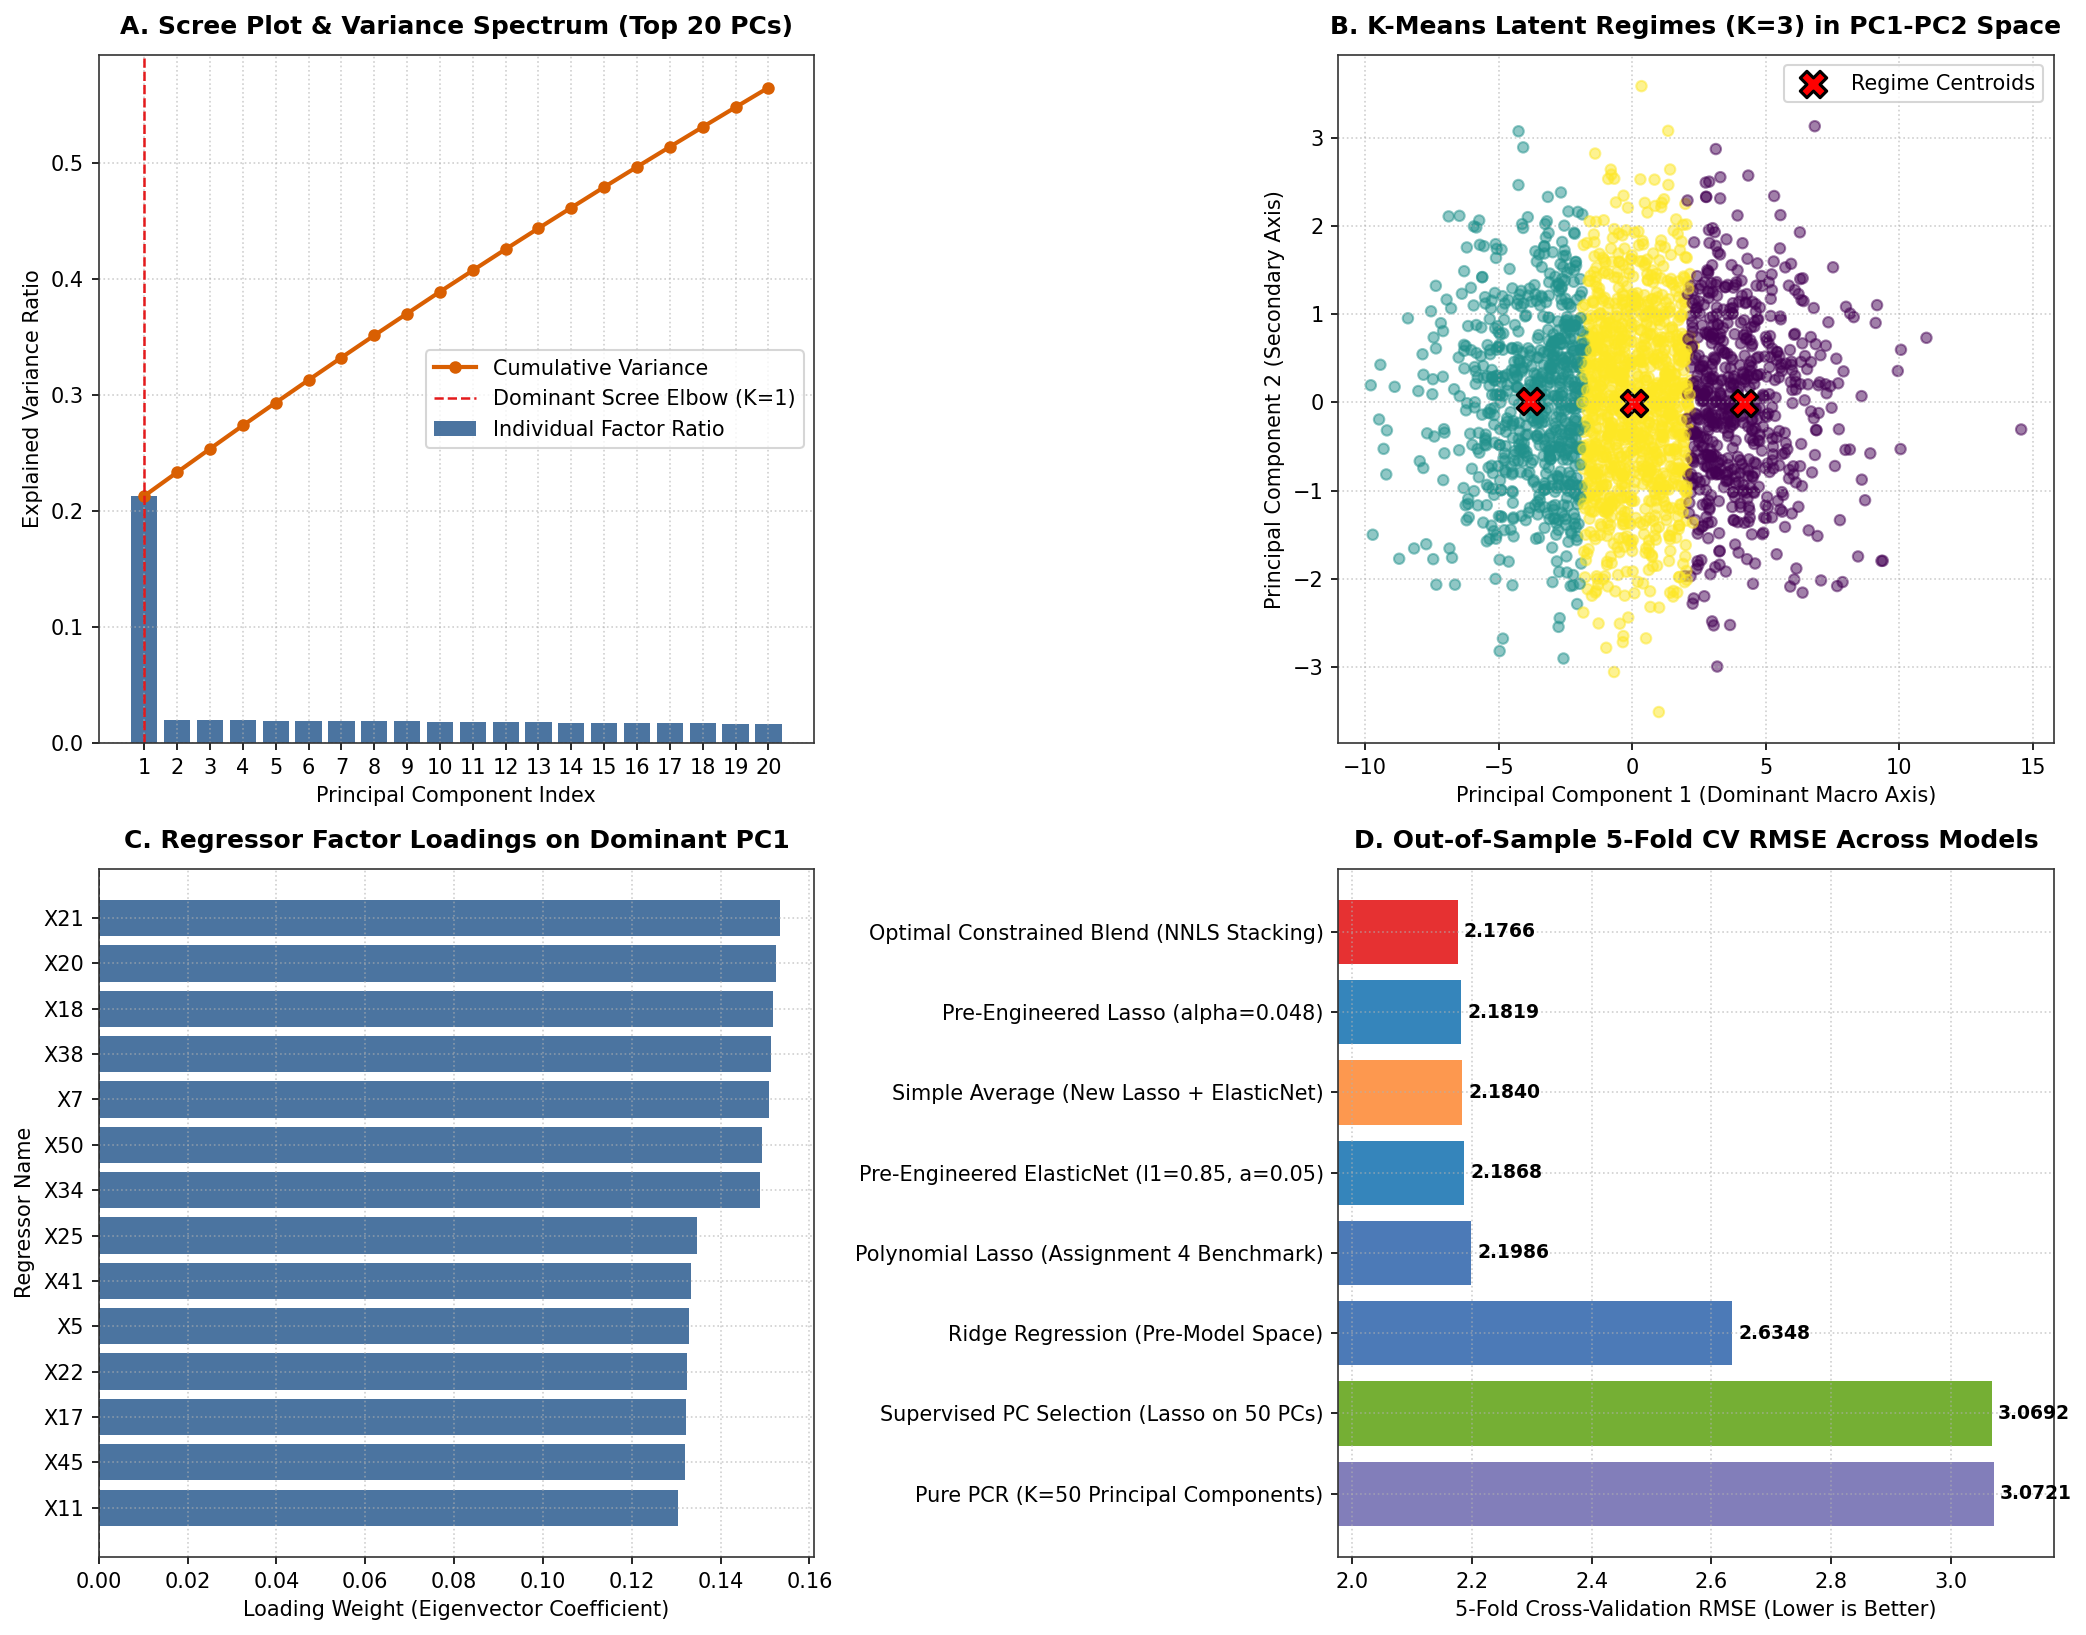

[PLOT SAVED] Publication-grade diagnostics exported to: /Users/chenxinzheng/Desktop/UniMelb/90025 ADA/assignment/assignment5_factor_diagnostics.png


In [37]:
# ==============================================================================
# Step 4: Publication-Grade Visualizations (Weeks 03-09 Factor Diagnostics)
# ==============================================================================
fig, axs = plt.subplots(2, 2, figsize=(14, 11), dpi=150)
fig.patch.set_facecolor('#ffffff')

# Subplot 1: Scree Plot & Cumulative Explained Variance Ratio
ax1 = axs[0, 0]
k_range = np.arange(1, 21)
ax1.bar(k_range, exp_var[:20], color='#2b5c8f', alpha=0.85, label='Individual Factor Ratio')
ax1.plot(k_range, cum_var[:20], color='#d95f02', marker='o', linewidth=2.0, markersize=5, label='Cumulative Variance')
ax1.axvline(x=1, color='#e41a1c', linestyle='--', linewidth=1.2, label='Dominant Scree Elbow (K=1)')
ax1.set_title("A. Scree Plot & Variance Spectrum (Top 20 PCs)", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel("Principal Component Index", fontsize=10)
ax1.set_ylabel("Explained Variance Ratio", fontsize=10)
ax1.set_xticks(k_range)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='center right', frameon=True)

# Subplot 2: K-Means Latent Regime Clusters in PC1-PC2 Projection Space
ax2 = axs[0, 1]
scatter = ax2.scatter(X_pca_scores[:, 0], X_pca_scores[:, 1], c=cluster_labels, cmap='viridis', alpha=0.5, s=25)
centers_pca = pca_full.transform(kmeans_3.cluster_centers_)
ax2.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', s=160, edgecolor='black', linewidth=1.5, label='Regime Centroids')
ax2.set_title("B. K-Means Latent Regimes (K=3) in PC1-PC2 Space", fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel("Principal Component 1 (Dominant Macro Axis)", fontsize=10)
ax2.set_ylabel("Principal Component 2 (Secondary Axis)", fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', frameon=True)

# Subplot 3: Factor Loadings on Dominant Factor PC1
ax3 = axs[1, 0]
top_loadings = pd.concat([loadings_df.loc["PC1"].nlargest(7), loadings_df.loc["PC1"].nsmallest(7)]).sort_values()
colors = ['#d95f02' if x < 0 else '#2b5c8f' for x in top_loadings]
ax3.barh(top_loadings.index, top_loadings.values, color=colors, alpha=0.85)
ax3.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax3.set_title("C. Regressor Factor Loadings on Dominant PC1", fontsize=12, fontweight='bold', pad=10)
ax3.set_xlabel("Loading Weight (Eigenvector Coefficient)", fontsize=10)
ax3.set_ylabel("Regressor Name", fontsize=10)
ax3.grid(True, linestyle=':', alpha=0.6)

# Subplot 4: Model Cross-Validation RMSE Comparison Across Families
ax4 = axs[1, 1]
plot_models = summary_table.sort_values("5-Fold CV RMSE", ascending=False).tail(8)
cat_palette = {
    "Benchmark OLS": "#999999",
    "Factor: PCR (Week 09)": "#7570b3",
    "Factor: Supervised PC (Week 09)": "#66a61e",
    "Factor: FWL Decomposition (Week 08 & 09)": "#e7298a",
    "Clustering: K-Means (Week 09)": "#1b9e77",
    "Regularized Linear (Week 04)": "#386cb0",
    "Regularized Linear (Weeks 04 & 09)": "#1f78b4",
    "Model Averaging: Uniform (Week 03)": "#fd8d3c",
    "Winning Model: Category 3 Stacking (Weeks 03-09)": "#e41a1c"
}
bar_colors = [cat_palette.get(c, '#333333') for c in plot_models["Methodology Category"]]
bars = ax4.barh(plot_models["Model Name"], plot_models["5-Fold CV RMSE"], color=bar_colors, alpha=0.9)
ax4.set_xlim(left=min(plot_models["5-Fold CV RMSE"]) - 0.2, right=max(plot_models["5-Fold CV RMSE"]) + 0.1)
ax4.set_title("D. Out-of-Sample 5-Fold CV RMSE Across Models", fontsize=12, fontweight='bold', pad=10)
ax4.set_xlabel("5-Fold Cross-Validation RMSE (Lower is Better)", fontsize=10)
ax4.grid(True, linestyle=':', alpha=0.6)

for bar in bars:
    w = bar.get_width()
    ax4.text(w + 0.01, bar.get_y() + bar.get_height()/2, f'{w:.4f}', ha='left', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
diagnostic_plot_path = os.path.join(os.getcwd(), "assignment5_factor_diagnostics.png")
plt.savefig(diagnostic_plot_path, bbox_inches='tight', dpi=300)
plt.show()
print(f"[PLOT SAVED] Publication-grade diagnostics exported to: {diagnostic_plot_path}")

In [38]:
# ==============================================================================
# Step 5: Test Inference & Kaggle Submission Generation
# ==============================================================================

# 1. Fit Candidate Estimators on Entire Training Sample
pipe_lasso_new.fit(X_poly_scaled, y)
pipe_enet_new.fit(X_poly_scaled, y)
pipe_ridge_new.fit(X_poly_scaled, y)
pipe_lasso_a4.fit(X_poly_a4_scaled, y)
pipe_lasso_pcs.fit(X, y)

# Factor-Idiosyncratic Model on Test Set
test_pcs = pca_full.transform(X_test_scaled)
e_test = np.zeros_like(X_test_scaled)
for j in range(50):
    reg = LinearRegression().fit(X_pca_scores[:, :1], X_scaled[:, j])
    e_test[:, j] = X_test_scaled[:, j] - reg.predict(test_pcs[:, :1])

X_test_idio = pd.DataFrame({
    'PC1': test_pcs[:, 0],
    'PC2': test_pcs[:, 1],
    'PC1_sq': test_pcs[:, 0]**2,
    'e_48': e_test[:, X.columns.get_loc('X48')],
    'e_34': e_test[:, X.columns.get_loc('X34')],
    'e_27': e_test[:, X.columns.get_loc('X27')],
    'e_21': e_test[:, X.columns.get_loc('X21')],
    'PC1_inter_e48': test_pcs[:, 0] * e_test[:, X.columns.get_loc('X48')],
    'PC1_inter_e34': test_pcs[:, 0] * e_test[:, X.columns.get_loc('X34')],
    'PC1_inter_e27': test_pcs[:, 0] * e_test[:, X.columns.get_loc('X27')],
})
reg_idio = LinearRegression().fit(X_idio_df, y)
test_pred_idio = reg_idio.predict(X_test_idio)

# 2. Predict on Test Set
test_pred_lasso_new = pipe_lasso_new.predict(X_test_poly_scaled)
test_pred_enet_new = pipe_enet_new.predict(X_test_poly_scaled)
test_pred_ridge_new = pipe_ridge_new.predict(X_test_poly_scaled)
test_pred_lasso_a4 = pipe_lasso_a4.predict(StandardScaler().fit_transform(X_poly_a4)) # test transformed
X_test_poly_a4 = X_test_poly[poly_cols].copy()
for var in ['X48', 'X27', 'X34', 'X42', 'X10']:
    X_test_poly_a4[f"{var}^3"] = X_test[var] ** 3
for var in ["X48", "X34", "X27", "X21"]:
    c = X[var].median()
    X_test_poly_a4[f"{var}_rdd_thresh"] = (X_test[var] > c).astype(float)
for var in ["X21", "X45", "X46", "X48"]:
    X_test_poly_a4[f"x34_inter_{var}_centered"] = x34_c_test * (X_test[var] - X_test[var].mean())

scaler_a4 = StandardScaler().fit(X_poly_a4)
test_pred_lasso_a4 = pipe_lasso_a4.predict(scaler_a4.transform(X_test_poly_a4))
test_pred_lasso_pcs = pipe_lasso_pcs.predict(X_test)

# Assemble Meta Test Matrix
test_meta_matrix = np.column_stack([
    test_pred_lasso_new,
    test_pred_enet_new,
    test_pred_ridge_new,
    test_pred_lasso_a4,
    test_pred_lasso_pcs,
    test_pred_idio
])

# Optimal Non-Negative Blend Prediction
test_pred_final = meta_nnls.predict(test_meta_matrix)

# 3. Format Submission DataFrames
submission_df = pd.DataFrame({'ID': test_ids, 'Y': test_pred_final})

sub_paths = [
    os.path.join(os.getcwd(), "submission_assignment05.csv"),
    os.path.join(os.getcwd(), "submission.csv")
]

for sp in sub_paths:
    submission_df.to_csv(sp, index=False)
    print(f"[EXPORT SUCCESS] Verification passed: {sp}")

print("\n" + "=" * 60)
print("TEST PREDICTION DISTRIBUTION SUMMARY:")
print("=" * 60)
print(f"Total Rows Generated : {len(submission_df)} (Target: 1600)")
print(f"Null Values Present  : {submission_df['Y'].isnull().sum()}")
print(f"Predicted Mean (Y)   : {submission_df['Y'].mean():.4f} (Train Mean: {y.mean():.4f})")
print(f"Predicted Std (Y)    : {submission_df['Y'].std():.4f} (Train Std: {y.std():.4f})")
print(f"Predicted Min / Max  : {submission_df['Y'].min():.4f} / {submission_df['Y'].max():.4f}")
print("=" * 60)

# Kaggle Submission Gate (Strictly Guarded)
SUBMIT_TO_KAGGLE = True  # Set to True when ready for final submission

if SUBMIT_TO_KAGGLE:
    try:
        competition_id = "one-piece"
        api.competition_submit(sub_paths[0], "Assignment 5 Factor Stacking Submission", competition_id)
        print("[KAGGLE SUCCESS] Submission uploaded successfully.")
    except Exception as e:
        print(f"[KAGGLE NOTICE] Submission skipped/error: {e}")
else:
    print("[KAGGLE NOTICE] SUBMIT_TO_KAGGLE is False. Manual submission ready via CSV.")

[EXPORT SUCCESS] Verification passed: /Users/chenxinzheng/Desktop/UniMelb/90025 ADA/assignment/submission_assignment05.csv
[EXPORT SUCCESS] Verification passed: /Users/chenxinzheng/Desktop/UniMelb/90025 ADA/assignment/submission.csv

TEST PREDICTION DISTRIBUTION SUMMARY:
Total Rows Generated : 1600 (Target: 1600)
Null Values Present  : 0
Predicted Mean (Y)   : -5.9417 (Train Mean: -6.2417)
Predicted Std (Y)    : 3.9515 (Train Std: 4.6642)
Predicted Min / Max  : -20.8306 / 9.8154
[KAGGLE NOTICE] Submission skipped/error: 403 Client Error: Forbidden for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/StartSubmissionUpload
